In [139]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import statsmodels
from statsmodels.tsa.seasonal import MSTL
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
import os
import glob
import pandas as pd

In [140]:
HIERARCHY_LEVELS = {
    "total": [],
    "state": ["state_id"],
    "store": ["store_id"],
    "category": ["cat_id"],
    "department": ["dept_id"],
    "state_category": ["state_id", "cat_id"],
    "state_department": ["state_id", "dept_id"],
    "store_category": ["store_id", "cat_id"],
    "store_department": ["store_id", "dept_id"],
    "item": ["item_id"],
    "state_item": ["item_id", "state_id"],
    "item_store": ["item_id", "store_id"],
}


def calculate_hierarchy_scales(train_df: pd.DataFrame):
    results = []

    for level, group_cols in HIERARCHY_LEVELS.items():
        if group_cols:
            daily_sales = (
                train_df.groupby(by=group_cols + ["date"], as_index=False)["sales"]
                .sum()
                .sort_values(by=group_cols + ["date"])
                .reset_index(drop=True)
            )

            daily_sales["cum_sales"] = daily_sales.groupby(group_cols)["sales"].cumsum()
            sales_started = daily_sales["cum_sales"].shift(1) > 0

            daily_sales["previous_sales"] = daily_sales.groupby(group_cols)[
                "sales"
            ].shift(1)

            daily_sales["diff_sq"] = (
                (daily_sales["sales"] - daily_sales["previous_sales"])
                .pow(2)
                .where(sales_started)
            )

            scale_df = (
                daily_sales.groupby(by=group_cols)["diff_sq"]
                .mean()
                .reset_index(name="scale")
            )
            scale_df["series_id"] = scale_df[group_cols].agg("_".join, axis=1)

        else:
            daily_sales = (
                train_df.groupby(by="date", as_index=False)["sales"]
                .sum()
                .sort_values(by="date")
                .reset_index(drop=True)
            )

            daily_sales["diff_sq"] = daily_sales["sales"].diff().pow(2)
            scale_df = pd.DataFrame(
                {"series_id": ["total"], "scale": daily_sales["diff_sq"].mean()}
            )

        scale_df["level"] = level

        results.append(scale_df[["level", "series_id", "scale"]])

    return pd.concat(results, ignore_index=True)


def calculate_hierarchy_mse(val_df: pd.DataFrame):

    results = []

    for level, group_cols in HIERARCHY_LEVELS.items():
        if group_cols:
            daily = val_df.groupby(by=group_cols + ["date"], as_index=False).agg(
                actual=("sales", sum), prediction=("prediction", sum)
            )

            daily["error_sq"] = (daily["actual"] - daily["prediction"]).pow(2)
            mse_df = (
                daily.groupby(by=group_cols)["error_sq"].mean().reset_index(name="mse")
            )
            mse_df["series_id"] = mse_df[group_cols].agg("_".join, axis=1)
        else:
            daily = val_df.groupby(by="date", as_index=False).agg(
                actual=("sales", sum), prediction=("prediction", sum)
            )
            daily["error_sq"] = (daily["actual"] - daily["prediction"]).pow(2)
            mse_df = pd.DataFrame(
                {"series_id": ["total"], "mse": daily["error_sq"].mean()}
            )

        mse_df["level"] = level
        results.append(mse_df[["level", "series_id", "mse"]])

    return pd.concat(results, ignore_index=True)


def calculate_hierarchy_weights(train_df: pd.DataFrame):
    results = []

    weight_df = train_df[
        train_df["date"] > train_df["date"].max() - pd.Timedelta(days=28)
    ]

    weight_df["dollar_sales"] = weight_df["sales"] * weight_df["sell_price"]

    results = []
    for level, group_col in HIERARCHY_LEVELS.items():
        if group_col:
            level_weight = (
                weight_df.groupby(by=group_col, as_index=False)["dollar_sales"]
                .sum()
                .reset_index()
            )
            level_weight["series_id"] = (
                level_weight[group_col].astype(str).agg("_".join, axis=1)
            )
        else:
            level_weight = pd.DataFrame(
                {
                    "series_id": ["total"],
                    "dollar_sales": weight_df["dollar_sales"].sum(),
                }
            )

        level_weight["level"] = level
        results.append(level_weight[["level", "series_id", "dollar_sales"]])

    return pd.concat(results, ignore_index=True)

## Error Analysis for LightGBM Global Model

In [141]:
#SALES_PATH = "../data/processed/*.parquet"


GOLD_PATH = "../data/gold/features.parquet"

In [142]:
# testing connection and reading data
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns",None)

con = duckdb.connect()

df = con.execute(f"""select * from read_parquet('{GOLD_PATH}') where year>=2015 and year<=2016 order by date""").df()
df.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,item_id,store_id,state_id,cat_id,dept_id,d,date,wm_yr_wk,launch_date,year,month,weekday,sell_price,event_name_1,event_type_1,snap,sales,week_of_year,day_of_week,day_of_month,is_weekend,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_35,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_42,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_49,lag_28,lag_29,lag_30,lag_31,lag_32,lag_33,lag_34,lag_56,rolling_positive_rate_7,rolling_positive_rate_28,rolling_zero_rate_28,days_since_last_sale,rolling_mean_7,rolling_mean_28,rolling_mean_56,rolling_positive_mean_7,rolling_positive_mean_28,rolling_positive_median_28,rolling_positive_std_28,rolling_positive_max_28,price_unique_count,price_max,price_min,price_mean,price_norm,price_weekly_change,price_change_m,price_change_y,price_vs_usual,price_vs_dept,store_dept_rolling_avg,enc_item_mean,enc_item_std,enc_store_mean,enc_store_std,enc_item_store_mean,enc_item_store_std,enc_store_dept_mean,enc_store_dept_std,enc_store_cat_mean,enc_store_cat_std,trend_28_vs_long,trend_7_vs_28,trend_28_vs_56,item_vs_dept,item_vs_cat,item_store_vs_global
0,FOODS_2_312,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2013-01-01,2015,1,Thursday,4.62,NewYear,National,1,2,1,4,1,0,0,0,1,0,2,1,0,0,1,3,0,0,2,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,2,0,2,0.29,0.29,0.71,31,0.43,0.43,0.43,1.5,1.25,1.0,0.46,2,3,5.26,4.62,4.88,0.88,1.00,1.00,0.98,0.95,1.13,327.57,0.317594,0.708290,1.142743,3.640201,0.291607,0.578854,0.928419,1.990224,1.634637,4.768026,1.817512,1.0,1.0,0.570863,0.324231,0.918177
1,FOODS_2_345,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2013-10-12,2015,1,Thursday,8.47,NewYear,National,1,0,1,4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0.00,0.25,0.75,39,0.00,0.00,0.00,NaN,1.00,1.0,0.00,1,3,8.47,3.00,8.31,1.00,1.00,1.00,1.00,1.02,2.07,327.57,0.507374,1.151171,1.142743,3.640201,0.300716,0.728947,0.928419,1.990224,1.634637,4.768026,0.332540,1.0,1.0,0.107710,0.061176,0.592691
2,FOODS_2_108,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2013-03-16,2015,1,Thursday,0.99,NewYear,National,1,0,1,4,1,0,0,0,0,1,0,6,0,0,1,2,1,0,0,0,1,0,0,0,1,0,0,1,0,3,1,1,1,0,0,0,0,0,0.43,0.32,0.68,28,0.43,0.43,0.43,1.0,1.22,1.0,0.67,3,5,3.44,0.99,3.08,0.29,0.33,0.35,0.31,0.32,0.24,327.57,0.862298,1.198954,1.142743,3.640201,0.610493,0.879319,0.928419,1.990224,1.634637,4.768026,0.868151,1.0,1.0,0.570863,0.324231,0.707984
3,FOODS_2_114,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2014-06-14,2015,1,Thursday,2.77,NewYear,National,1,0,1,4,1,0,0,0,0,1,1,1,0,0,1,1,1,2,1,1,0,0,1,2,0,1,1,4,0,0,3,0,0,1,0,0,0,1,0.29,0.43,0.57,28,0.57,0.57,0.57,2.0,1.33,1.0,0.65,3,2,2.77,2.73,2.74,1.00,1.00,1.00,1.01,1.01,0.68,327.57,0.813732,1.226412,1.142743,3.640201,0.827586,0.952112,0.928419,1.990224,1.634637,4.768026,0.809583,1.0,1.0,0.721657,0.409877,1.017026
4,FOODS_2_383,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2014-06-14,2015,1,Thursday,1.87,NewYear,National,1,0,1,4,1,0,0,0,0,0,4,0,1,0,0,0,3,0,0,4,1,0,0,0,1,0,0,4,0,3,0,1,0,0,0,1,0,1,0.29,0.32,0.68,29,0.29,0.29,0.29,1.0,1.78,1.0,0.97,3,2,1.88,1.87,1.87,0.99,1.00,1.00,1.00,1.00,0.46,327.57,1.912483,2.486020,1.142743,3.640201,0.580460,1.113173,0.928419,1.990224,1.634637,4.768026,0.671881,1.0,1.0,0.420069,0.238585,0.303511


In [143]:
df["d"].max()

np.uint16(1941)

In [144]:
df["date"].max()

Timestamp('2016-05-22 00:00:00')

In [145]:
train_df = df[df["d"]<=1913]
test_df = df[df["d"]>1913]

In [146]:
print(f"test start date: {test_df["date"].min()}, test ends: {test_df["date"].max()}, total rows: {len(test_df)}")

test start date: 2016-04-25 00:00:00, test ends: 2016-05-22 00:00:00, total rows: 853720


In [147]:
test_df = pd.read_parquet("../artifacts/test_predictions_ensemble.parquet") # already predictions

In [148]:
print(f"test start date: {test_df["date"].min()}, test ends: {test_df["date"].max()}, total rows: {len(test_df)}")

test start date: 2016-04-25 00:00:00, test ends: 2016-05-22 00:00:00, total rows: 853720


In [149]:
test_df["series_id"] = test_df["item_id"].astype(str) + "_" + test_df["store_id"].astype(str)
test_df.head()

,item_id,store_id,cat_id,dept_id,state_id,date,sales,sell_price,pred_global,pred_store,prediction,series_id
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,2.98,0.839267,0.858988,0.849128,FOODS_3_112_TX_2
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,2016-04-25,0,1.98,0.163945,0.166827,0.165386,FOODS_3_380_TX_2
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,2.50,1.082707,1.128969,1.105838,FOODS_3_719_TX_2
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2016-04-25,3,2.98,0.764992,0.777275,0.771133,FOODS_3_104_TX_2
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,2016-04-25,11,1.68,13.931995,13.512494,13.722244,FOODS_3_080_TX_2


In [150]:
scale_df = calculate_hierarchy_scales(train_df)
weights_df = calculate_hierarchy_weights(train_df)
mse_df = calculate_hierarchy_mse(test_df) # for ensemble

In [151]:
test_unique_df = test_df[["item_id","store_id","cat_id","dept_id","state_id","series_id"]].drop_duplicates()
len(test_unique_df)

30490

In [ ]:
merge_df = test_unique_df.merge(scale_df, on="series_id", how="inner")
merge_df = merge_df.merge(mse_df, on="series_id", how="inner")
merge_df = merge_df.merge(weights_df, on="series_id", how="inner")
merge_df.drop(columns=["level_x","level_y","level","series_id"], inplace=True)
merge_df["rmsse"] = merge_df["mse"]/merge_df["scale"]
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609
...,...,...,...,...,...,...,...,...,...,...
30485,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720
30486,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449
30487,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405
30488,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872


In [153]:
merge_df[merge_df["scale"].isna()]
# there are 16 item-store combinations which has scale as zero and hence the rmsse, so I have dropped these rows for further analysis

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse
6007,FOODS_2_053,WI_1,FOODS,FOODS_2,WI,NaN,0.006307,item_store,0.0,NaN
10137,FOODS_2_394,TX_3,FOODS,FOODS_2,TX,NaN,0.005109,item_store,0.0,NaN
10433,FOODS_2_129,TX_3,FOODS,FOODS_2,TX,NaN,0.266979,item_store,0.0,NaN
11778,FOODS_3_751,CA_4,FOODS,FOODS_3,CA,NaN,1.293718,item_store,0.0,NaN
23294,HOUSEHOLD_1_356,CA_3,HOUSEHOLD,HOUSEHOLD_1,CA,NaN,0.238640,item_store,0.0,NaN
23952,HOBBIES_1_210,CA_1,HOBBIES,HOBBIES_1,CA,NaN,0.011189,item_store,0.0,NaN
25071,HOUSEHOLD_1_356,CA_4,HOUSEHOLD,HOUSEHOLD_1,CA,NaN,0.006384,item_store,0.0,NaN
25694,HOBBIES_1_335,WI_1,HOBBIES,HOBBIES_1,WI,NaN,3.156219,item_store,0.0,NaN
26136,HOBBIES_1_335,CA_3,HOBBIES,HOBBIES_1,CA,NaN,2.047298,item_store,0.0,NaN
26882,HOBBIES_1_335,CA_2,HOBBIES,HOBBIES_1,CA,NaN,0.091686,item_store,0.0,NaN


In [154]:
merge_df = merge_df.dropna()

In [155]:
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609
...,...,...,...,...,...,...,...,...,...,...
30485,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720
30486,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449
30487,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405
30488,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872


In [156]:
import numpy as np


test_price_df = (
    test_df.groupby(["item_id", "store_id"], observed=True)["sell_price"]
    .mean()
    .reset_index(name="mean_price")
)
test_price_df["price_band"] = pd.cut(
    test_price_df["mean_price"],
    bins=[0, 1, 2, 5, 10, np.inf],
    labels=["<$1", "$1-2", "$2-5", "$5-10", "$10+"],
    right=False
)
test_price_df["price_band"] = test_price_df["price_band"].astype("object").fillna("no price")

merge_df = merge_df.merge(test_price_df, on=["item_id","store_id"], how="left")
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814,2.98,$2-5
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438,1.98,$1-2
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798,2.50,$2-5
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563,2.98,$2-5
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609,1.68,$1-2
...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720,0.50,<$1
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449,0.97,<$1
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405,5.97,$5-10
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872,0.50,<$1


In [157]:
last_train_date = train_df["date"].max()
last28 = train_df[train_df["date"] > train_df["date"].max() - pd.Timedelta(days=28)]

volume_df = last28.groupby(["item_id","store_id"])["sales"].mean().reset_index(name="mean_sales")
merge_df = merge_df.merge(volume_df, on=["item_id","store_id"], how="left")

In [158]:
merge_df["volume_decile"] = "D00 no sales"
pos = merge_df["mean_sales"] > 0
ranks = merge_df.loc[pos, "mean_sales"].rank(method="first")
merge_df.loc[pos, "volume_decile"] = pd.qcut(
    ranks, 10, labels=[f"D{d:02d}" for d in range(1, 11)]
).astype(str)

merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales,volume_decile
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814,2.98,$2-5,0.785714,D06
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438,1.98,$1-2,0.000000,D00 no sales
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798,2.50,$2-5,0.285714,D03
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563,2.98,$2-5,1.428571,D08
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609,1.68,$1-2,15.964286,D10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720,0.50,<$1,0.000000,D00 no sales
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449,0.97,<$1,0.357143,D04
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405,5.97,$5-10,0.178571,D02
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872,0.50,<$1,0.035714,D01


In [159]:
last_train_date = train_df["date"].max()
last91 = train_df[train_df["date"] > last_train_date - pd.Timedelta(days=91)]
intermittency_df = (
    (last91["sales"] > 0)
    .groupby([last91["item_id"], last91["store_id"]], observed=True)
    .mean()
    .reset_index(name="nonzero_rate")
)

merge_df = merge_df.merge(intermittency_df, on=["item_id", "store_id"], how="left")
merge_df["sell_frequency"] = pd.cut(
    merge_df["nonzero_rate"],
    bins=[0, 0.10, 0.50, 1.0001],
    labels=["high intermittency (<10% sell days)",
        "medium intermittency (10-50%)",
        "low intermittency (>=50%)"],
    right=False,
)
merge_df["sell_frequency"] = merge_df["sell_frequency"].astype("object").fillna("unknown")
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales,volume_decile,nonzero_rate,sell_frequency
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814,2.98,$2-5,0.785714,D06,0.681319,low intermittency (>=50%)
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438,1.98,$1-2,0.000000,D00 no sales,0.021978,high intermittency (<10% sell days)
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798,2.50,$2-5,0.285714,D03,0.527473,low intermittency (>=50%)
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563,2.98,$2-5,1.428571,D08,0.637363,low intermittency (>=50%)
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609,1.68,$1-2,15.964286,D10,1.000000,low intermittency (>=50%)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720,0.50,<$1,0.000000,D00 no sales,0.000000,high intermittency (<10% sell days)
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449,0.97,<$1,0.357143,D04,0.208791,medium intermittency (10-50%)
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405,5.97,$5-10,0.178571,D02,0.065934,high intermittency (<10% sell days)
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872,0.50,<$1,0.035714,D01,0.032967,high intermittency (<10% sell days)


In [167]:
def slice_unwighted(df,col):
    g = df.groupby(col, observed=True)["rmsse"]
    tbl = pd.DataFrame({"n_series":g.size(),"mean_rmsse":g.mean(),"median_rmsse":g.median()})
    tbl["share_of_series"]=tbl["n_series"]/tbl["n_series"].sum()
    return tbl.sort_values("median_rmsse",ascending=False)

for col in ["store_id", "cat_id", "dept_id", "price_band", "volume_decile", "sell_frequency",["store_id","cat_id"]]:
    print(f"\n===== RMSSE by {col} =====")
    print(slice_unwighted(merge_df,col).round(3))


===== RMSSE by store_id =====
          n_series  mean_rmsse  median_rmsse  share_of_series
store_id                                                     
CA_2          3048       0.844         0.574              0.1
WI_2          3048       0.753         0.529              0.1
TX_3          3046       0.749         0.515              0.1
WI_3          3048       0.730         0.515              0.1
CA_4          3046       0.709         0.513              0.1
CA_3          3047       0.731         0.507              0.1
CA_1          3048       0.828         0.502              0.1
WI_1          3047       0.674         0.485              0.1
TX_2          3048       0.650         0.473              0.1
TX_1          3048       0.694         0.461              0.1

===== RMSSE by cat_id =====
           n_series  mean_rmsse  median_rmsse  share_of_series
cat_id                                                        
FOODS         14366       0.779         0.527            0.471
HOUSEHO

In [161]:
print(
    merge_df.pivot_table(
        index="cat_id", columns="sell_frequency",
        values="rmsse", aggfunc="median",
    ).round(3)
)

sell_frequency  high intermittency (<10% sell days)  \
cat_id                                                
FOODS                                         0.565   
HOUSEHOLD                                     0.488   
HOBBIES                                       0.482   

sell_frequency  low intermittency (>=50%)  medium intermittency (10-50%)  
cat_id                                                                    
FOODS                               0.528                          0.519  
HOUSEHOLD                           0.499                          0.492  
HOBBIES                             0.471                          0.476  


In [ ]:
merge_df["dollar_sales"] = merge_df["dollar_sales"].fillna(0)
merge_df["weight"] = merge_df["dollar_sales"] / merge_df["dollar_sales"].sum()
merge_df["contribution"] = merge_df["weight"] * merge_df["rmsse"]

In [163]:
print("sum of weights:", merge_df["weight"].sum())                        # 1.0
print("series with weight 0:", (merge_df["weight"] == 0).sum())
print("item-store level score:", merge_df["contribution"].sum())

sum of weights: 1.0
series with weight 0: 1571
item-store level score: 0.7707420437169152


In [191]:
score = (merge_df["weight"]*merge_df["rmsse"]).sum()
print("item-store level wrmsse score is : ",round(score,4))

item-store level wrmsse score is :  0.7707


In [192]:
print("sum of weights:", round(merge_df["weight"].sum(), 4))      # must be 1.0
print("series:", len(merge_df))                                    # about 30,474
print("item-store score:", round(score, 4))

sum of weights: 1.0
series: 30474
item-store score: 0.7707


In [193]:
def slice_weighted(df, col):
    g = df.groupby(col, observed=True)
    total_contribution = df["contribution"].sum()

    tbl = pd.DataFrame({
        "n_series": g.size(),
        "weight_share": g["weight"].sum(),
        "error_share": g["contribution"].sum() / total_contribution,
        "weighted_rmsse": g["contribution"].sum() / g["weight"].sum(),
        "median_rmsse": g["rmsse"].median(),
    })
    tbl["excess_share"] = tbl["error_share"] - tbl["weight_share"]
    return tbl.sort_values("error_share", ascending=False)


for col in ["store_id", "cat_id", "dept_id", "price_band", "volume_decile", "sell_frequency"]:
    print(f"\n===== weighted error by {col} =====")
    print(slice_weighted(merge_df, col).round(3))


===== weighted error by store_id =====
          n_series  weight_share  error_share  weighted_rmsse  median_rmsse  \
store_id                                                                      
CA_3          3047         0.156        0.157           0.776         0.507   
WI_2          3048         0.117        0.124           0.821         0.529   
CA_2          3048         0.110        0.121           0.845         0.574   
CA_1          3048         0.111        0.106           0.736         0.502   
TX_3          3046         0.097        0.099           0.788         0.515   
TX_2          3048         0.095        0.088           0.713         0.473   
WI_3          3048         0.085        0.088           0.800         0.515   
WI_1          3047         0.087        0.079           0.699         0.485   
TX_1          3048         0.078        0.078           0.777         0.461   
CA_4          3046         0.066        0.060           0.711         0.513   

          e

In [194]:
merge_df["rmsse_gt_1"] = merge_df["rmsse"] > 1

In [201]:
merge_df[merge_df["rmsse"]>1]

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales,volume_decile,nonzero_rate,sell_frequency,weight,contribution,rmsse_gt_1
11,FOODS_3_423,TX_2,FOODS,FOODS_3,TX,2.754202,3.078970,item_store,151.979996,1.117917,2.98,$2-5,1.821429,D09,0.780220,low intermittency (>=50%),0.000041,0.000045,True
20,FOODS_3_266,TX_2,FOODS,FOODS_3,TX,0.358491,0.359292,item_store,24.360001,1.002236,3.48,$2-5,0.250000,D03,0.186813,medium intermittency (10-50%),0.000006,0.000007,True
29,FOODS_3_009,TX_2,FOODS,FOODS_3,TX,3.400000,4.848939,item_store,59.279999,1.426159,2.28,$2-5,0.928571,D07,0.560440,low intermittency (>=50%),0.000016,0.000023,True
33,FOODS_3_549,TX_2,FOODS,FOODS_3,TX,1.599581,2.500499,item_store,32.700001,1.563221,2.18,$2-5,0.535714,D05,0.395604,medium intermittency (10-50%),0.000009,0.000014,True
35,FOODS_3_543,TX_2,FOODS,FOODS_3,TX,0.492693,0.523937,item_store,40.279999,1.063415,3.48,$2-5,0.428571,D04,0.197802,medium intermittency (10-50%),0.000011,0.000011,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30450,HOBBIES_2_043,CA_4,HOBBIES,HOBBIES_2,CA,0.876050,0.936867,item_store,0.000000,1.069422,0.97,<$1,0.000000,D00 no sales,0.054945,high intermittency (<10% sell days),0.000000,0.000000,True
30453,HOBBIES_2_064,CA_4,HOBBIES,HOBBIES_2,CA,0.119891,0.137853,item_store,3.880000,1.149822,0.97,<$1,0.142857,D02,0.043956,high intermittency (<10% sell days),0.000001,0.000001,True
30456,HOBBIES_2_133,CA_4,HOBBIES,HOBBIES_2,CA,0.229122,0.451216,item_store,11.520000,1.969324,2.88,$2-5,0.142857,D02,0.054945,high intermittency (<10% sell days),0.000003,0.000006,True
30458,HOBBIES_2_128,CA_4,HOBBIES,HOBBIES_2,CA,0.350835,0.713624,item_store,9.940000,2.034072,4.97,$2-5,0.071429,D01,0.065934,high intermittency (<10% sell days),0.000003,0.000005,True


In [195]:
def flag_summary(df, flag):
    bad = df[flag]
    total_contribution = df["contribution"].sum()
    return pd.Series({
        "n_series": len(df),
        "n_bad": bad.sum(),
        "share_of_series": bad.mean(),
        "weight_share": df.loc[bad, "weight"].sum(),
        "error_share": df.loc[bad, "contribution"].sum() / total_contribution,
    })

print(flag_summary(merge_df, "rmsse_gt_1").round(3))

n_series           30474.000
n_bad               4926.000
share_of_series        0.162
weight_share           0.179
error_share            0.447
dtype: float64


In [196]:
show_cols = [
    "item_id", "store_id", "dept_id",
    "price_band", "volume_decile", "sell_frequency",
    "mse", "scale", "rmsse", "weight", "contribution",
]
bad_df = merge_df[merge_df["rmsse_gt_1"]]

In [197]:
print("=== worst RMSSE ===")
print(bad_df.sort_values("rmsse", ascending=False)[show_cols].head(10).round(4))

=== worst RMSSE ===
               item_id store_id      dept_id price_band volume_decile  \
24142    HOBBIES_1_335     CA_1    HOBBIES_1       $10+  D00 no sales   
10001      FOODS_1_088     CA_1      FOODS_1      $5-10           D07   
7876       FOODS_3_664     CA_3      FOODS_3       $1-2           D09   
23595  HOUSEHOLD_1_321     CA_3  HOUSEHOLD_1       $2-5           D08   
29793    HOBBIES_1_091     TX_1    HOBBIES_1        <$1           D03   
22309  HOUSEHOLD_1_089     CA_2  HOUSEHOLD_1      $5-10  D00 no sales   
23479  HOUSEHOLD_1_336     CA_3  HOUSEHOLD_1       $2-5  D00 no sales   
8395       FOODS_3_538     CA_3      FOODS_3       $1-2  D00 no sales   
4010       FOODS_3_444     WI_2      FOODS_3      $5-10  D00 no sales   
29612    HOBBIES_1_215     TX_1    HOBBIES_1       $10+           D03   

                            sell_frequency        mse    scale     rmsse  \
24142  high intermittency (<10% sell days)     0.6944   0.0022  314.5814   
10001            low int

In [198]:
print("=== biggest contribution ===")
print(bad_df.sort_values("contribution", ascending=False)[show_cols].head(10).round(4))

=== biggest contribution ===
               item_id store_id      dept_id price_band volume_decile  \
23459  HOUSEHOLD_1_106     CA_3  HOUSEHOLD_1      $5-10           D10   
10001      FOODS_1_088     CA_1      FOODS_1      $5-10           D07   
3689       FOODS_3_811     WI_2      FOODS_3       $1-2           D10   
23595  HOUSEHOLD_1_321     CA_3  HOUSEHOLD_1       $2-5           D08   
4859       FOODS_3_702     WI_3      FOODS_3       $2-5           D10   
11446      FOODS_1_129     TX_3      FOODS_1      $5-10           D10   
23406  HOUSEHOLD_1_357     CA_3  HOUSEHOLD_1       $10+           D10   
7111       FOODS_3_702     WI_1      FOODS_3       $2-5           D10   
7876       FOODS_3_664     CA_3      FOODS_3       $1-2           D09   
23551  HOUSEHOLD_1_494     CA_3  HOUSEHOLD_1      $5-10           D10   

                      sell_frequency       mse     scale    rmsse  weight  \
23459      low intermittency (>=50%)  132.2256   39.8539   3.3178  0.0010   
10001      lo

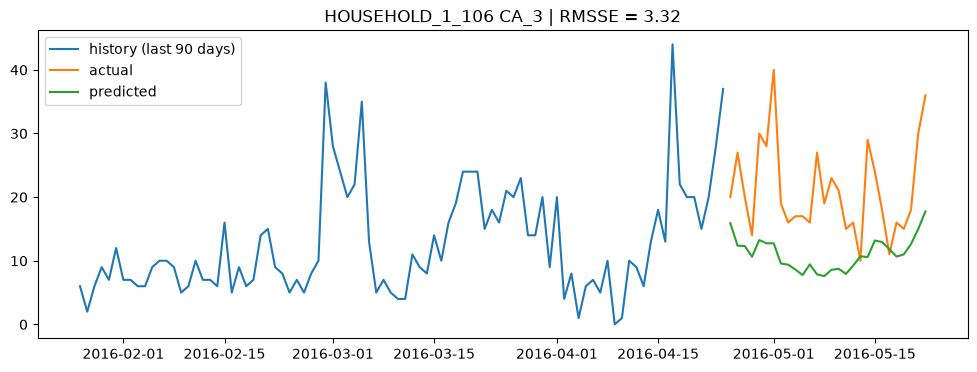

In [199]:
import matplotlib.pyplot as plt

row = bad_df.sort_values("contribution", ascending=False).iloc[0]   # top from View B
item, store = row["item_id"], row["store_id"]

hist = train_df[(train_df["item_id"] == item) & (train_df["store_id"] == store)].tail(90)
fc = test_df[(test_df["item_id"] == item) & (test_df["store_id"] == store)]

plt.figure(figsize=(12, 4))
plt.plot(hist["date"], hist["sales"], label="history (last 90 days)")
plt.plot(fc["date"], fc["sales"], label="actual")
plt.plot(fc["date"], fc["pred_global"], label="predicted")
plt.title(f"{item} {store} | RMSSE = {row['rmsse']:.2f}")
plt.legend()
plt.show()